# Прогноз по доходам и расходам

Телефонный маркетинг срочного депозита, [UCI Bank Marketing](https://archive.ics.uci.edu/ml/datasets/bank+marketing).
Звонок стоит 2 доллара. Если клиент открывает депозит, банк получает 10 долларов.
Звоним только тем, кого модель отнесла к положительному классу.

Целевая переменная — согласие клиента. `duration` не используем: до звонка её нет.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["axes.unicode_minus"] = False


In [3]:
df = pd.read_csv("bank-additional/bank-additional-full.csv", sep=";")
print(f"Контактов: {len(df)}, доля согласий: {(df.y == 'yes').mean():.1%}")
display(df.drop(columns="duration").head(3))


Контактов: 41188, доля согласий: 11.3%


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Категории кодируем one-hot, числа стандартизируем. Метрики качества — ROC-AUC и average precision.
Модель — логистическая регрессия, оценка по стратифицированной кросс-валидации на 5 фолдов.


In [4]:
X = df.drop(columns=["duration", "y"])
y = df.y == "yes"

cat_cols = X.select_dtypes(include="str").columns.tolist()
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
encoder = ColumnTransformer([
    ("cats", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("nums", StandardScaler(), num_cols),
])
encoded = pd.DataFrame(
    encoder.fit_transform(X),
    columns=encoder.get_feature_names_out(),
)


def out_of_fold(X, y, C=1.0, random_state=42):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    parts = []
    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):
        model = LogisticRegression(C=C, max_iter=1000)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        parts.append(pd.DataFrame({
            "fold": fold,
            "y": y.iloc[test_idx].to_numpy(),
            "proba": model.predict_proba(X.iloc[test_idx])[:, 1],
        }))
    return pd.concat(parts, ignore_index=True)


def call_profit(y_true, proba, threshold=0.5, random_revenue=False):
    y_true = np.asarray(y_true).astype(int)
    call = np.asarray(proba) > threshold
    subscribed = int((call & (y_true == 1)).sum())
    calls = int(call.sum())
    if random_revenue and subscribed:
        revenue = float(np.random.uniform(0, 20, subscribed).sum())
    else:
        revenue = 10 * subscribed
    expenses = 2 * calls
    return revenue - expenses, expenses


def evaluate(predictions, threshold=0.5, random_revenue=False):
    rows = []
    for _, group in predictions.groupby("fold"):
        profit, expenses = call_profit(group.y, group.proba, threshold, random_revenue)
        call = group.proba.to_numpy() > threshold
        rows.append({
            "roc_auc": roc_auc_score(group.y, group.proba),
            "average_precision": average_precision_score(group.y, group.proba),
            "precision": precision_score(group.y, call, zero_division=0),
            "recall": recall_score(group.y, call, zero_division=0),
            "profit": profit,
            "expenses": expenses,
        })
    return pd.DataFrame(rows)


baseline_pred = out_of_fold(encoded, y)
baseline = evaluate(baseline_pred)
display(baseline.round(3))


,roc_auc,average_precision,precision,recall,profit,expenses
0,0.789,0.435,0.629,0.189,1194,556
1,0.786,0.434,0.677,0.228,1494,626
2,0.804,0.485,0.697,0.278,1840,740
3,0.788,0.447,0.652,0.232,1490,660
4,0.792,0.459,0.653,0.219,1408,622


## Прибыль

Оператору платим 2 доллара за каждый звонок. Депозит приносит 10 долларов.
Прибыль фолда = `10 * TP − 2 * (TP + FP)`.


In [5]:
print(f"Средняя прибыль на фолд: {baseline.profit.mean():.0f} $")
print(f"Стандартное отклонение: {baseline.profit.std(ddof=1):.0f} $")
print(f"Средний расход на операторов: {baseline.expenses.mean():.0f} $")

for column in ("roc_auc", "average_precision"):
    r, pvalue = stats.pearsonr(baseline[column], baseline.profit)
    print(f"{column}: r = {r:.2f}, p = {pvalue:.2f}")


Средняя прибыль на фолд: 1485 $
Стандартное отклонение: 233 $
Средний расход на операторов: 641 $
roc_auc: r = 0.76, p = 0.14
average_precision: r = 0.80, p = 0.10


По пяти фолдам связь прибыли с ROC-AUC и average precision сильная, но незначимая.
Дальше модель выбираем по прибыли.

Если согласие приносит не 10 долларов, а случайную величину из \(U[0, 20)\), картина почти не меняется:
ожидаемая выручка та же.


In [6]:
random_profit = evaluate(baseline_pred, random_revenue=True)
compare = pd.DataFrame({
    "фиксированные 10 $": baseline.profit,
    "случайная выручка": random_profit.profit,
})
display(compare.round(1))


,фиксированные 10 $,случайная выручка
0,1194,1262.6
1,1494,1511.2
2,1840,1696.3
3,1490,1539.4
4,1408,1269.1


## Коэффициент регуляризации

Ищем `C` по средней случайной прибыли. Сетку запускаем три раза с разными разбиениями на фолды.


seed 42: лучший C = 100
seed 777: лучший C = 100
seed 123: лучший C = 10


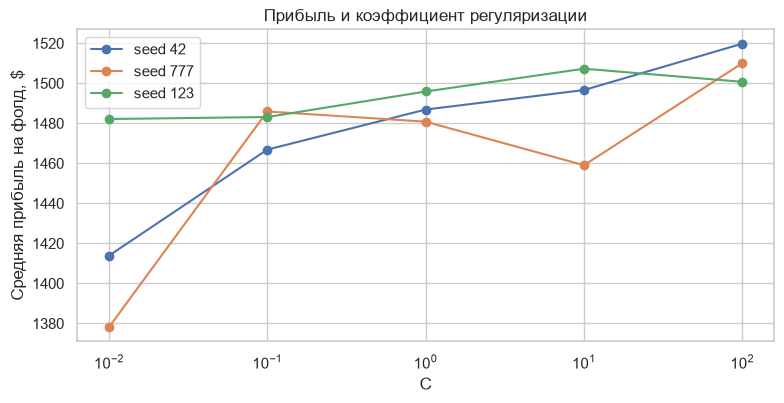

In [7]:
C_grid = np.logspace(-2, 2, 5)
seeds = (42, 777, 123)

fig, ax = plt.subplots(figsize=(8, 4.2))
best_C = {}
for seed in seeds:
    means = []
    for C in C_grid:
        pred = out_of_fold(encoded, y, C=float(C), random_state=seed)
        means.append(evaluate(pred, random_revenue=True).profit.mean())
    best_C[seed] = C_grid[int(np.argmax(means))]
    ax.plot(C_grid, means, marker="o", label=f"seed {seed}")

ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("Средняя прибыль на фолд, $")
ax.set_title("Прибыль и коэффициент регуляризации")
ax.legend(frameon=True)
fig.tight_layout()

for seed, C in best_C.items():
    print(f"seed {seed}: лучший C = {C:g}")


Лучший `C` от запуска к запуску меняется, кривая почти плоская. Подбор регуляризации почти не увеличивает прибыль.


## Порог

Для этой цены звонка важнее полнота, чем точность: пропущенный клиент стоит дороже лишнего звонка.
Порог снижаем и смотрим, растёт ли прибыль. Сетка от 0 до 1 с шагом 0.01.


,precision,recall,profit
порог 0.5,0.662,0.229,1485.2
порог 0.19,0.422,0.575,2806.4


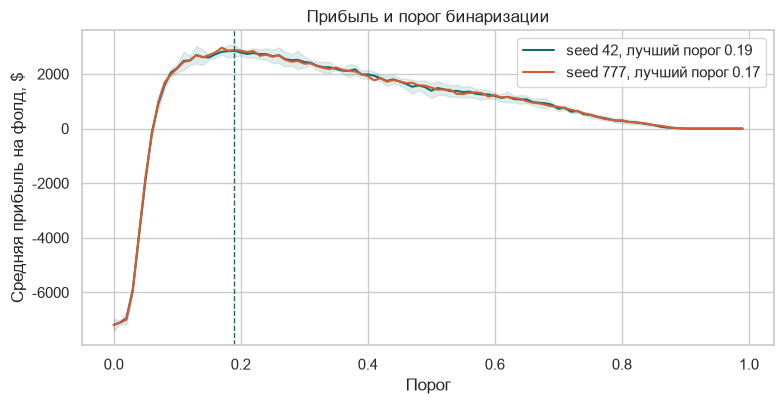

In [ ]:
thresholds = np.round(np.arange(0, 1, 0.01), 2)

def threshold_curve(random_state):
    pred = out_of_fold(encoded, y, C=1.0, random_state=random_state)
    means, stds = [], []
    for threshold in thresholds:
        profit = evaluate(pred, threshold=threshold, random_revenue=True).profit
        means.append(profit.mean())
        stds.append(profit.std(ddof=1))
    return pred, np.array(means), np.array(stds)

pred_42, mean_42, std_42 = threshold_curve(42)
pred_777, mean_777, std_777 = threshold_curve(777)
best_42 = thresholds[int(mean_42.argmax())]
best_777 = thresholds[int(mean_777.argmax())]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(thresholds, mean_42, color="#0F6E6E", label=f"seed 42, лучший порог {best_42:.2f}")
ax.fill_between(thresholds, mean_42 - std_42, mean_42 + std_42, color="#0F6E6E", alpha=0.12)
ax.plot(thresholds, mean_777, color="#D85A30", label=f"seed 777, лучший порог {best_777:.2f}")
ax.axvline(best_42, color="#0F6E6E", linestyle="--", linewidth=1)
ax.set_xlabel("Порог")
ax.set_ylabel("Средняя прибыль на фолд, $")
ax.set_title("Прибыль и порог бинаризации")
ax.legend(frameon=True)
fig.tight_layout()




Оба раза лучший порог около 0.2: полнота вырастает, точность падает, прибыль растёт.


## Дефолтная модель и настроенная

Дефолт: `C = 1`, порог 0.5. Настроенная: `C = 0.1`, порог около 0.2.
Сравниваем прибыль по фолдам парным t-критерием.


In [9]:
default_model = evaluate(out_of_fold(encoded, y, C=1.0, random_state=42), threshold=0.5, random_revenue=True)
tuned_model = evaluate(out_of_fold(encoded, y, C=0.1, random_state=42), threshold=0.2, random_revenue=True)

side_by_side = pd.DataFrame({
    "дефолт": default_model.profit,
    "настроенная": tuned_model.profit,
})
display(side_by_side.round(1))
print(f"Среднее и ст. откл., дефолт: {default_model.profit.mean():.0f} ± {default_model.profit.std(ddof=1):.0f}")
print(f"Среднее и ст. откл., настроенная: {tuned_model.profit.mean():.0f} ± {tuned_model.profit.std(ddof=1):.0f}")

t_stat, p_value = stats.ttest_rel(default_model.profit, tuned_model.profit)
print(f"t = {t_stat:.2f}, p = {p_value:.4f}")


,дефолт,настроенная
0,1118.3,2687.8
1,1513.7,2528.8
2,1801.5,3014.4
3,1546.4,2605.7
4,1419.7,2965.8


Среднее и ст. откл., дефолт: 1480 ± 247
Среднее и ст. откл., настроенная: 2760 ± 218
t = -10.86, p = 0.0004


Прибыль настроенной модели выше на каждом фолде, отличие значимо.


## Какие признаки тянут согласие

Коэффициенты той же логистической регрессии. Плюс — выше шанс открыть депозит, минус — ниже.


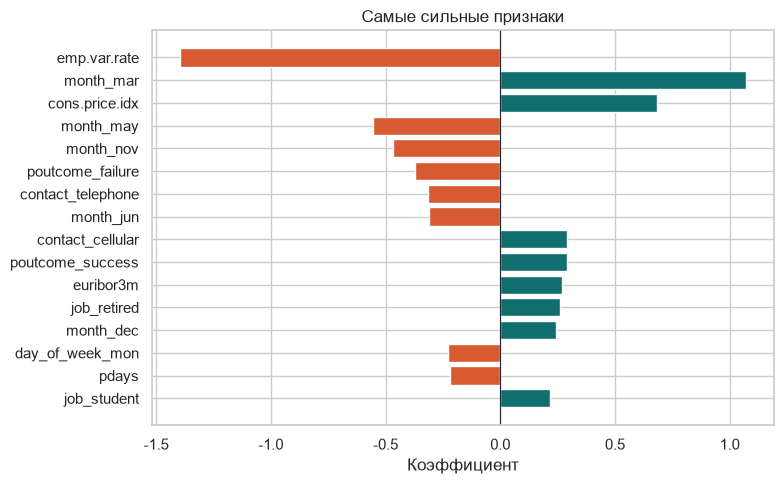

In [13]:
model = LogisticRegression(C=0.1, max_iter=1000)
model.fit(encoded, y)
coefficients = pd.Series(model.coef_[0], index=encoded.columns)
coefficients.index = [name.split("__", 1)[-1] for name in coefficients.index]
top = pd.concat([coefficients.nsmallest(8), coefficients.nlargest(8)])
top = top.sort_values(key = np.abs, ascending = True)


fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#D85A30" if value < 0 else "#0F6E6E" for value in top]
ax.barh(top.index, top.to_numpy(), color=colors)
ax.axvline(0, color="#1F2933", linewidth=0.8)
ax.set_xlabel("Коэффициент")
ax.set_title("Самые сильные признаки")
fig.tight_layout()


На графике не шестнадцать отдельных причин, а четыре группы.

**Прошлая кампания.** `poutcome_success` — человеку уже предлагали депозит, и он согласился. 

**Канал.** мобильный (`contact_cellular`) и стационарный (`contact_telephone`). 

**Кто клиент.** Студенты и пенсионеры. 

**Когда звонили.** Месяц здесь без года и помечает волну обзвона, а не «удачный календарный месяц». Понедельник чуть хуже остальных дней, коэффициент маленький.

**Экономический фон и `pdays`.** `emp.var.rate` — квартальное изменение занятости. Чем оно ниже, тем чаще берут депозит: корреляция с согласием около −0.30, это самый большой отрицательный коэффициент. Плюс у `euribor3m` и `cons.price.idx` отдельно читать не стоит. Эти ряды ходят вместе с занятостью (корреляции примерно 0.7–0.97), и модель делит один сигнал на три столбца. Сам по себе Euribor с согласием связан отрицательно.

`pdays` — дни с прошлого контакта, а 999 значит «раньше не звонили», так помечено 96% строк. Большое значение в столбце почти всегда означает отсутствие истории, поэтому коэффициент отрицательный.
